In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

import torch
from annadca import annaRBMbin
from annadca.dataset import annaDataset
from annadca.utils import get_eigenvalues_history
from annadca.plot import plot_PCA

In [2]:
fname_data = "../data/MNIST_train.csv"
fname_chains = "../models/MNIST_chains.fasta"
fname_model = "../models/MNIST_params.h5"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
dtype = torch.float32

# Import dataset
tokens = "01"
dataset = annaDataset(
    path_data=fname_data,
    column_names="name",
    column_sequences="sequence",
    column_labels="label",
    alphabet="01",
    device=device,
    dtype=dtype,
    is_binary=True,
)

data = dataset.data_one_hot
weights = dataset.weights.view(-1)
labels_data = dataset.to_label(dataset.labels_one_hot)

# Load the chains
rbm = annaRBMbin()
rbm.load(fname_model, device=device, dtype=dtype)
chains = rbm.load_chains(filename=fname_chains, alphabet=tokens, device=device, dtype=dtype)
labels_chains = dataset.to_label(chains["label"])

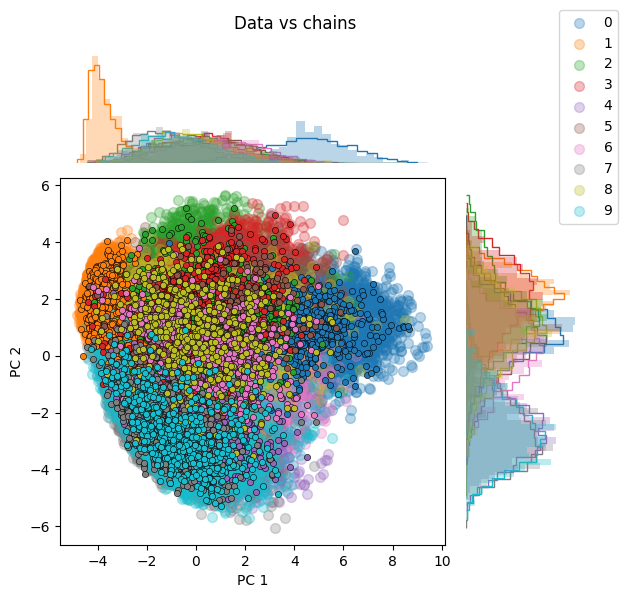

In [3]:
# Project data and chains on the same PCA space
pca = PCA(n_components=2)
data_proj = pca.fit_transform(data.cpu().numpy())
chains_proj = pca.transform(chains["visible"].view(len(chains["visible"]), -1).cpu().numpy())

# Define the colors
unique_labels = np.unique(labels_data)
cmap = plt.get_cmap("tab10", len(unique_labels))
label_to_color = {label.item(): cmap(i) for i, label in enumerate(unique_labels)}

fig = plt.figure(figsize=(6,6))
fig = plot_PCA(
    fig=fig,
    data1=data_proj,
    labels1=labels_data,
    data2=chains_proj,
    labels2=labels_chains,
    label_to_color=label_to_color,
    dim1=0,
    dim2=1,
    title="Data vs chains",
    split_labels=True,
)
fig.legend(bbox_to_anchor=(1.05, 1.0))
fig.tight_layout()

## Sample unconditioned

In [29]:
#chains_init = rbm.init_chains(num_samples=10000)
samples = rbm.sample(gibbs_steps=1000, num_samples=10000)
samples_proj = pca.transform(samples["visible"].view(len(samples["visible"]), -1).cpu().numpy())
samples_labels = dataset.to_label(samples["label"])

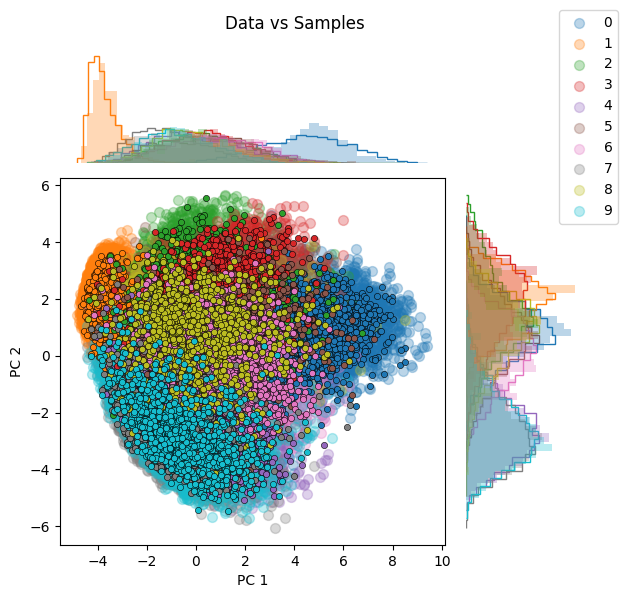

In [30]:
fig = plt.figure(figsize=(6,6))
fig = plot_PCA(
    fig=fig,
    data1=data_proj,
    labels1=labels_data,
    data2=samples_proj,
    labels2=samples_labels,
    label_to_color=label_to_color,
    dim1=0,
    dim2=1,
    title="Data vs Samples",
    split_labels=True,
)
fig.legend(bbox_to_anchor=(1.05, 1.0))
fig.tight_layout()

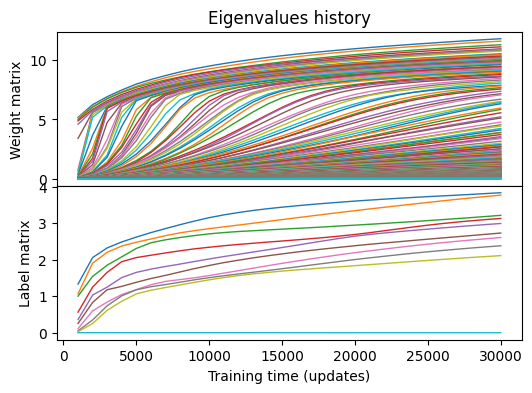

In [31]:
updates, eigenvalues = get_eigenvalues_history(fname_model, target_matrix="weight_matrix", device=device, dtype=dtype)
updates, eigenvalues_labels = get_eigenvalues_history(fname_model, target_matrix="label_matrix", device=device, dtype=dtype)

# Plot the eigenvalues history. first row is the weight matrix, second row is the label matrix.
fig, ax = plt.subplots(2, 1, figsize=(6, 4), sharex=True, gridspec_kw={'hspace': 0})
ax[0].plot(updates, eigenvalues, lw=1)
ax[1].plot(updates, eigenvalues_labels, lw=1)
ax[1].set_xlabel("Training time (updates)")
ax[0].set_ylabel("Weight matrix")
ax[1].set_ylabel("Label matrix")
ax[0].set_title("Eigenvalues history");

## Conditioned sampling

In [32]:
rbm.load(fname_model, device=device, dtype=dtype)
cond_chains = rbm.sample_conditioned(
    gibbs_steps=10000,
    targets=dataset.labels_one_hot,
)

In [33]:
cond_chains_proj = pca.transform(cond_chains["visible"].view(len(cond_chains["visible"]), -1).cpu().numpy())
cond_chains_labels = labels_data

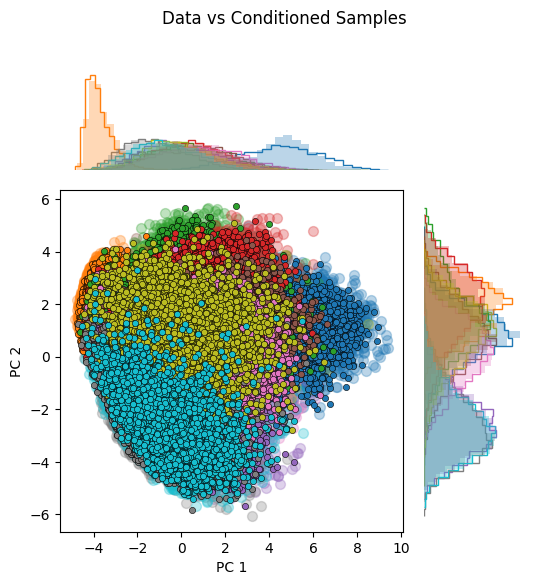

In [34]:
fig = plt.figure(figsize=(6,6))
fig = plot_PCA(
    fig=fig,
    data1=data_proj,
    labels1=labels_data,
    data2=cond_chains_proj,
    labels2=cond_chains_labels,
    label_to_color=label_to_color,
    dim1=0,
    dim2=1,
    title="Data vs Conditioned Samples",
    split_labels=True,
)

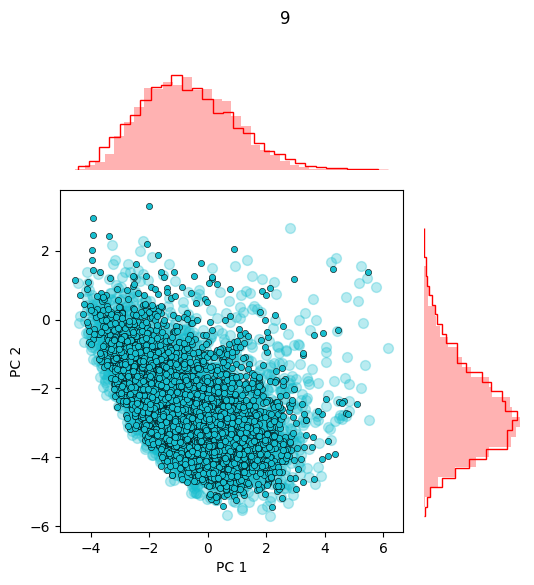

In [35]:
# Plot pca of conditioned chains and data but only one label
label_idx = 9
label = dataset.idx_to_label[label_idx]
mask_data = labels_data == label
mask_gen = cond_chains_labels == label
data_proj_label = data_proj[mask_data]
chains_proj_label = cond_chains_proj[mask_gen]

fig = plt.figure(figsize=(6,6))
fig = plot_PCA(
    fig=fig,
    data1=data_proj_label,
    labels1=labels_data[mask_data],
    data2=chains_proj_label,
    labels2=cond_chains_labels[mask_gen],
    label_to_color={label: cmap(label_idx)},
    dim1=0,
    dim2=1,
    title=label,
    split_labels=False,
)

## Predict labels of the data

In [9]:
# Train accuracy
predictions = rbm.predict_labels(visible=dataset.data_one_hot)
accuracy = (predictions.argmax(-1) == dataset.labels_one_hot.argmax(-1)).float().mean().item()
print(f"Train accuracy: {accuracy}")


fname_test = "../data/MNIST_test.csv"
dataset_test = annaDataset(
    path_data=fname_test,
    column_names="name",
    column_sequences="sequence",
    column_labels="label",
    alphabet="01",
    device=device,
    dtype=dtype,
    is_binary=True,
)
predictions = rbm.predict_labels(visible=dataset_test.data_one_hot)
accuracy = (predictions.argmax(-1) == dataset_test.labels_one_hot.argmax(-1)).float().mean().item()
print(f"Test accuracy: {accuracy}")

Train accuracy: 0.9320999979972839
Test accuracy: 0.9264999628067017


## Importance sampling

In [10]:
from typing import Dict, Tuple

def importance_sampling(
    rbm: annaRBMbin,
    num_samples: int,
    wild_type: torch.Tensor,
    ngibbs: int,
    importance_weight: float,
    beta: float = 1.0,
) -> Dict[str, torch.Tensor]:
    # replicate the wild type sequence
    samples = wild_type.unsqueeze(0).repeat(num_samples, 1)
    # modify the visible bias
    rbm_mod = rbm.clone()
    # positive bias on the wild type sites
    rbm_mod.params["vbias"] += importance_weight * wild_type
    # negative bias on the sites that are not in the wild type
    rbm_mod.params["vbias"] -= importance_weight * (1 - wild_type)
    samples = rbm_mod.sample(
        gibbs_steps=ngibbs,
        visible=samples,
        beta=beta,
    )
    return samples

def compute_Hdisc(rbm: annaRBMbin, samples: Dict[str, torch.Tensor], target_label_oh: torch.Tensor) -> torch.Tensor:
    fields = target_label_oh @ rbm.params["lbias"]
    interactions = (samples["hidden_mag"] @ rbm.params["label_matrix"].T @ target_label_oh)
    return - fields - interactions

def get_energy_contributions(
    rbm: annaRBMbin,
    samples: Dict[str, torch.Tensor],
    target_label_oh: torch.Tensor,
) -> Tuple[torch.Tensor, torch.Tensor]:
    # Generative energy
    Hgen = rbm.compute_energy_visibles(
        visible=samples["visible"],
        label=torch.zeros_like(samples["label"]),
    )
    # Discriminative energy
    # Hdisc = compute_Hdisc(rbm, samples, target_label_oh)
    # Label probability
    target_label_idx = target_label_oh.argmax(dim=-1)
    p_label = rbm.predict_labels(**samples)[:, target_label_idx]
    return Hgen, p_label

def get_distance_from_wt(
    wt: torch.Tensor,
    samples: Dict[str, torch.Tensor]
) -> torch.Tensor:
    return (samples["visible"] != wt).float().sum(-1)

### Calibration

In [11]:
import ipywidgets as widgets
from IPython.display import display

# Select a wild type sample and a target label
label_wt_interact = widgets.IntText(min=0, max=9, step=1, value=0, description="WT Label:")
label_target_interact = widgets.IntText(min=0, max=9, step=1, value=8, description="Target Label:")
wt_index_interact = widgets.IntText(min=0, max=100, step=1, value=0, description="WT Index:")

# Generation
importance_weight_interact = widgets.FloatText(min=0, max=1000, step=0.01, value=0.5, description="Lambda:")
num_samples_interact = widgets.IntText(min=1, max=50000, step=1, value=10000, description="Num Samples:")
ngibbs_interact = widgets.IntText(min=1, max=100000, step=1, value=1000, description="N Gibbs:")
beta_interact = widgets.FloatText(min=0, max=2, step=0.01, value=1.0, description="Beta:")

def plot_wt(label_wt, label_target, wt_index):
    wild_type = dataset.data_one_hot[dataset.data["label"].to_numpy() == label_wt][wt_index]
    plt.imshow(wild_type.reshape(28, 28).cpu().numpy(), cmap="gray")
    plt.title(f"Wild Type Digit: {label_wt}, index: {wt_index}")
    plt.axis("off")
    plt.show()

    print(f"Target Digit: {label_target}")
    
    return wild_type


def calibrate_and_plot(importance_weight, num_samples, ngibbs, beta, wild_type, wild_type_data_pca, target_data_pca):
    samples = importance_sampling(
        rbm=rbm,
        num_samples=num_samples,
        wild_type=wild_type,
        ngibbs=ngibbs,
        importance_weight=importance_weight,
        beta=beta,
    )
    distances = get_distance_from_wt(
        wt=wild_type,
        samples=samples,
    )
    
    # project wild type and samples in the PCA
    samples_pca = pca.transform(samples["visible"].cpu().numpy())
    wt_pca = pca.transform(wild_type.view(1, -1).cpu().numpy())

    plt.figure(figsize=(12, 6))
    plt.subplot(1, 2, 1)
    plt.scatter(wild_type_data_pca[:, 0], wild_type_data_pca[:, 1], alpha=0.3, label="WT-like data")
    plt.scatter(target_data_pca[:, 0], target_data_pca[:, 1], alpha=0.5, label="Target-like data")
    plt.scatter(samples_pca[:, 0], samples_pca[:, 1], alpha=0.5, label="Generated samples")
    plt.scatter(wt_pca[:, 0], wt_pca[:, 1], s=100, color='red', marker='d', label="Wild Type")
    plt.title("PCA of Generated Samples")
    plt.xlabel("PC 1")
    plt.ylabel("PC 2")
    plt.legend()
    plt.tight_layout()

    plt.subplot(1, 2, 2)
    plt.hist(distances.cpu().numpy(), bins=range(int(distances.min()), int(distances.max()) + 2), color='red', alpha=0.7)
    plt.title("Distance from WT Distribution")
    plt.xlabel("Hamming Distance")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()
    return samples
    
def plot_generated(samples):
    # plot 10 generated mnist samples
    fig, axes = plt.subplots(2, 5, figsize=(10, 4))
    for i, ax in enumerate(axes.flat):
        if i < len(samples["visible_mag"]):
            ax.imshow(samples["visible_mag"][i].reshape(28, 28).cpu().numpy(), cmap="gray")
            ax.set_title(f"Sample {i+1}")
        ax.axis("off")
    plt.tight_layout()
    plt.show()

def run_all(label_wt, label_target, wt_index, importance_weight, num_samples, ngibbs, beta):
    wild_type = plot_wt(label_wt, label_target, wt_index)
    wild_type_data = dataset.data_one_hot[dataset.data["label"].to_numpy() == label_wt]
    target_data = dataset.data_one_hot[dataset.data["label"].to_numpy() == label_target]
    
    # pca projection on wild type data and target data 
    wild_type_data_pca = pca.transform(wild_type_data.cpu().numpy())
    target_data_pca = pca.transform(target_data.cpu().numpy())

    samples = calibrate_and_plot(importance_weight, num_samples, ngibbs, beta, wild_type, wild_type_data_pca, target_data_pca)
    plot_generated(samples)

interaction = widgets.interact(run_all,
    label_wt=label_wt_interact,
    label_target=label_target_interact,
    wt_index=wt_index_interact,
    importance_weight=importance_weight_interact,
    num_samples=num_samples_interact,
    ngibbs=ngibbs_interact,
    beta=beta_interact,
)

interactive(children=(IntText(value=0, description='WT Label:'), IntText(value=8, description='Target Label:')…

Calibrating the sampling for different values of the `importance_weight`

| distance from wt | $\lambda_{opt}$ |
|------------------|----------------|
| 2                |        4.2        |
| 4                |        3.8        |
| 8                |        3        |
| 16               |        2.1        |
| 32               |         1.3       |
| 64               |          0.3      |
| 90               |          0.09      |
| 128              |          0.05      |

### Parenzio line

In [12]:
from sklearn.linear_model import LogisticRegression

logreg = LogisticRegression(max_iter=1000)
logreg.fit(
    dataset.data_one_hot.cpu().numpy(),
    dataset.data["label"].to_numpy()
)

train_accuracy = logreg.score(
    dataset.data_one_hot.cpu().numpy(),
    dataset.data["label"].to_numpy()
)

test_accuracy = logreg.score(
    dataset_test.data_one_hot.cpu().numpy(),
    dataset_test.data["label"].to_numpy()
)

print(f"Logistic Regression Train accuracy: {train_accuracy}")
print(f"Logistic Regression Test accuracy: {test_accuracy}")

Logistic Regression Train accuracy: 0.94015
Logistic Regression Test accuracy: 0.9057


In [13]:
def get_energy_logreg(samples, target_label_oh):
    idx_label = target_label_oh.argmax().item()
    betas = logreg.coef_[idx_label]
    Hdiscr = - samples["visible"].cpu().numpy() @ betas
    return Hdiscr

def get_prob_logreg(samples, target_label_oh):
    idx_label = target_label_oh.argmax().item()
    p_label = logreg.predict_proba(samples["visible"].cpu().numpy())[:, idx_label]
    return p_label

In [14]:
lambda_to_distance = {
    4.2: 2,
    3.8: 4,
    3.0: 8,
    2.1: 16,
    1.3: 32,
    0.3: 64,
    0.09: 90,
    0.05: 128,
}

distance_to_energies = {k: {} for k in lambda_to_distance.values()}

ngibbs = 5000
num_samples = 100000
beta = 1.0

wild_type = dataset.data_one_hot[dataset.data["label"].to_numpy() == label_wt_interact.value][wt_index_interact.value]
label_target_oh = dataset.labels_one_hot[dataset.data["label"].to_numpy() == label_target_interact.value][0]

for importance_weight, distance in lambda_to_distance.items():
    print(f"Importance weight: {importance_weight}, Target distance: {distance}")
    samples = importance_sampling(
        rbm=rbm,
        num_samples=num_samples,
        wild_type=wild_type,
        ngibbs=ngibbs,
        importance_weight=importance_weight,
        beta=beta,
    )
    distances = get_distance_from_wt(
        wt=wild_type,
        samples=samples,
    )

    # filter for sequences at a target distance
    samples_filtered = {k: v[distances == distance] for k, v in samples.items()}
    print(f"---> Extracted {len(samples_filtered['visible'])} samples at distance {distance}")

    Hgen, p_rbm = get_energy_contributions(
        rbm=rbm,
        samples=samples_filtered,
        target_label_oh=label_target_oh,
    )
    p_lr = get_prob_logreg(samples_filtered, label_target_oh)
    distance_to_energies[distance]["Hgen"] = Hgen.cpu().numpy()
    distance_to_energies[distance]["p_rbm"] = p_rbm.cpu().numpy()
    distance_to_energies[distance]["p_lr"] = p_lr
    distance_to_energies[distance]["samples"] = samples_filtered["visible_mag"].cpu().numpy()

Importance weight: 4.2, Target distance: 2
---> Extracted 26994 samples at distance 2
Importance weight: 3.8, Target distance: 4
---> Extracted 18910 samples at distance 4
Importance weight: 3.0, Target distance: 8
---> Extracted 13656 samples at distance 8
Importance weight: 2.1, Target distance: 16
---> Extracted 10580 samples at distance 16
Importance weight: 1.3, Target distance: 32
---> Extracted 7769 samples at distance 32
Importance weight: 0.3, Target distance: 64
---> Extracted 5411 samples at distance 64
Importance weight: 0.09, Target distance: 90
---> Extracted 1411 samples at distance 90
Importance weight: 0.05, Target distance: 128
---> Extracted 2058 samples at distance 128


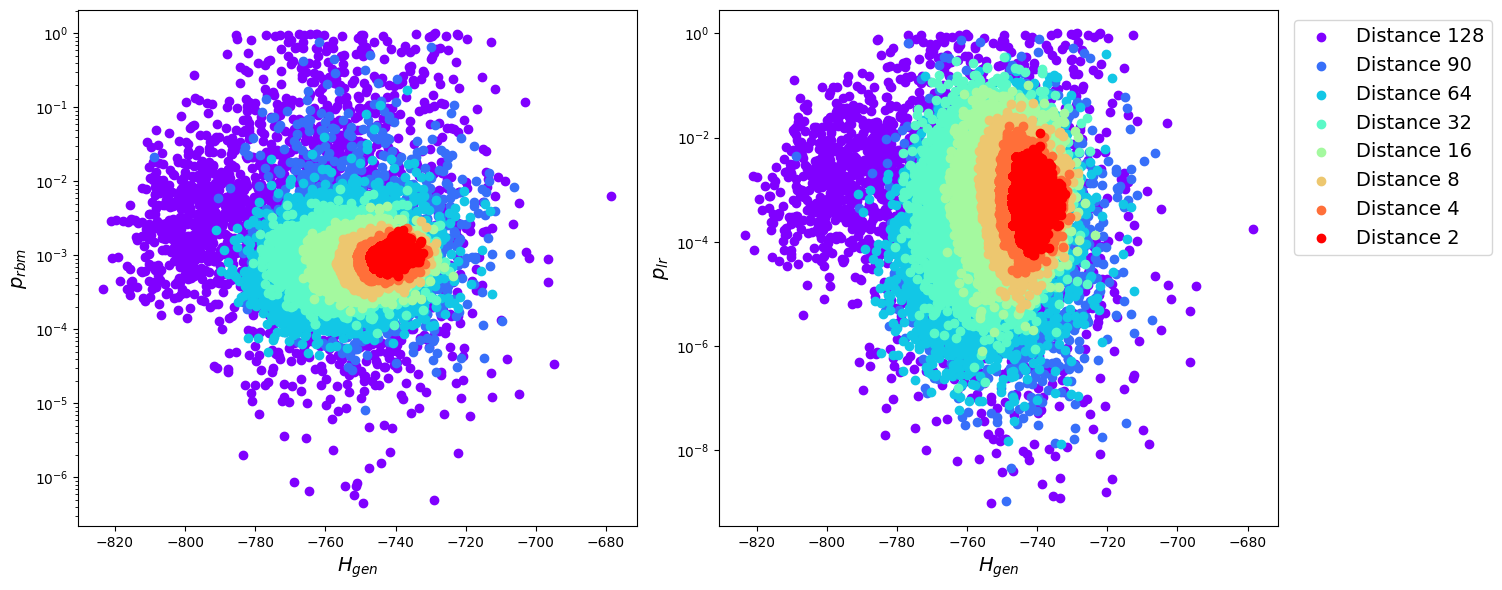

In [16]:
distance_plot = [2, 4, 8, 16, 32, 64, 90, 128]

fontsize = 14
colormap = plt.get_cmap("rainbow", len(distance_plot))

fig, ax = plt.subplots(1, 2, figsize=(15, 6), dpi=100)
ax[0].set_xlabel(r"$H_{gen}$", fontsize=fontsize)
ax[0].set_ylabel(r"$p_{rbm}$", fontsize=fontsize)
ax[0].set_yscale("log")
ax[1].set_xlabel(r"$H_{gen}$", fontsize=fontsize)
ax[1].set_ylabel(r"$p_{lr}$", fontsize=fontsize)
ax[1].set_yscale("log")

for i, distance in enumerate(reversed(distance_plot)):
    ax[0].scatter(distance_to_energies[distance]["Hgen"], distance_to_energies[distance]["p_rbm"],
               color=colormap(i), label=f"Distance {distance}")
    ax[1].scatter(distance_to_energies[distance]["Hgen"], distance_to_energies[distance]["p_lr"],
               color=colormap(i), label=f"Distance {distance}")
ax[1].legend(fontsize=fontsize, bbox_to_anchor=(1.4, 1.0))

fig.tight_layout()

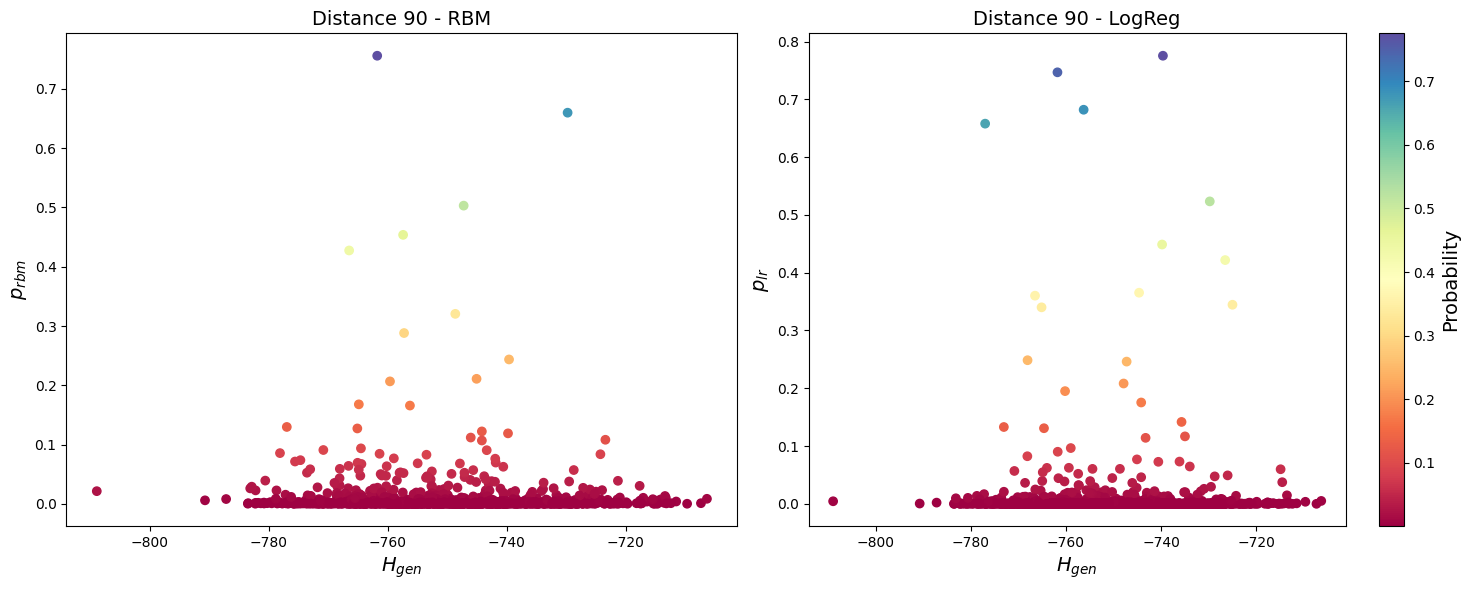

In [31]:
distance_plot = 90
fontsize = 14

Hgen_vals = distance_to_energies[distance_plot]["Hgen"]
p_rbm_vals = distance_to_energies[distance_plot]["p_rbm"]
p_lr_vals = distance_to_energies[distance_plot]["p_lr"]

fig, ax = plt.subplots(1, 2, figsize=(15, 6), dpi=100)
sc = ax[0].scatter(Hgen_vals, p_rbm_vals, c=p_rbm_vals, cmap="Spectral", label=f"Distance {distance_plot}")
ax[0].set_xlabel(r"$H_{gen}$", fontsize=fontsize)
ax[0].set_ylabel(r"$p_{rbm}$", fontsize=fontsize)
ax[0].set_title(f"Distance {distance_plot} - RBM", fontsize=fontsize)

sc = ax[1].scatter(Hgen_vals, p_lr_vals, c=p_lr_vals, cmap="Spectral", label=f"Distance {distance_plot}")
ax[1].set_xlabel(r"$H_{gen}$", fontsize=fontsize)
ax[1].set_ylabel(r"$p_{lr}$", fontsize=fontsize)
ax[1].set_title(f"Distance {distance_plot} - LogReg", fontsize=fontsize)

cbar = plt.colorbar(sc, ax=ax[1])
cbar.set_label(r"Probability", fontsize=fontsize)
fig.tight_layout()

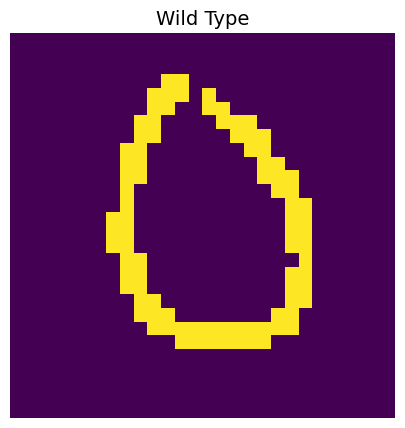

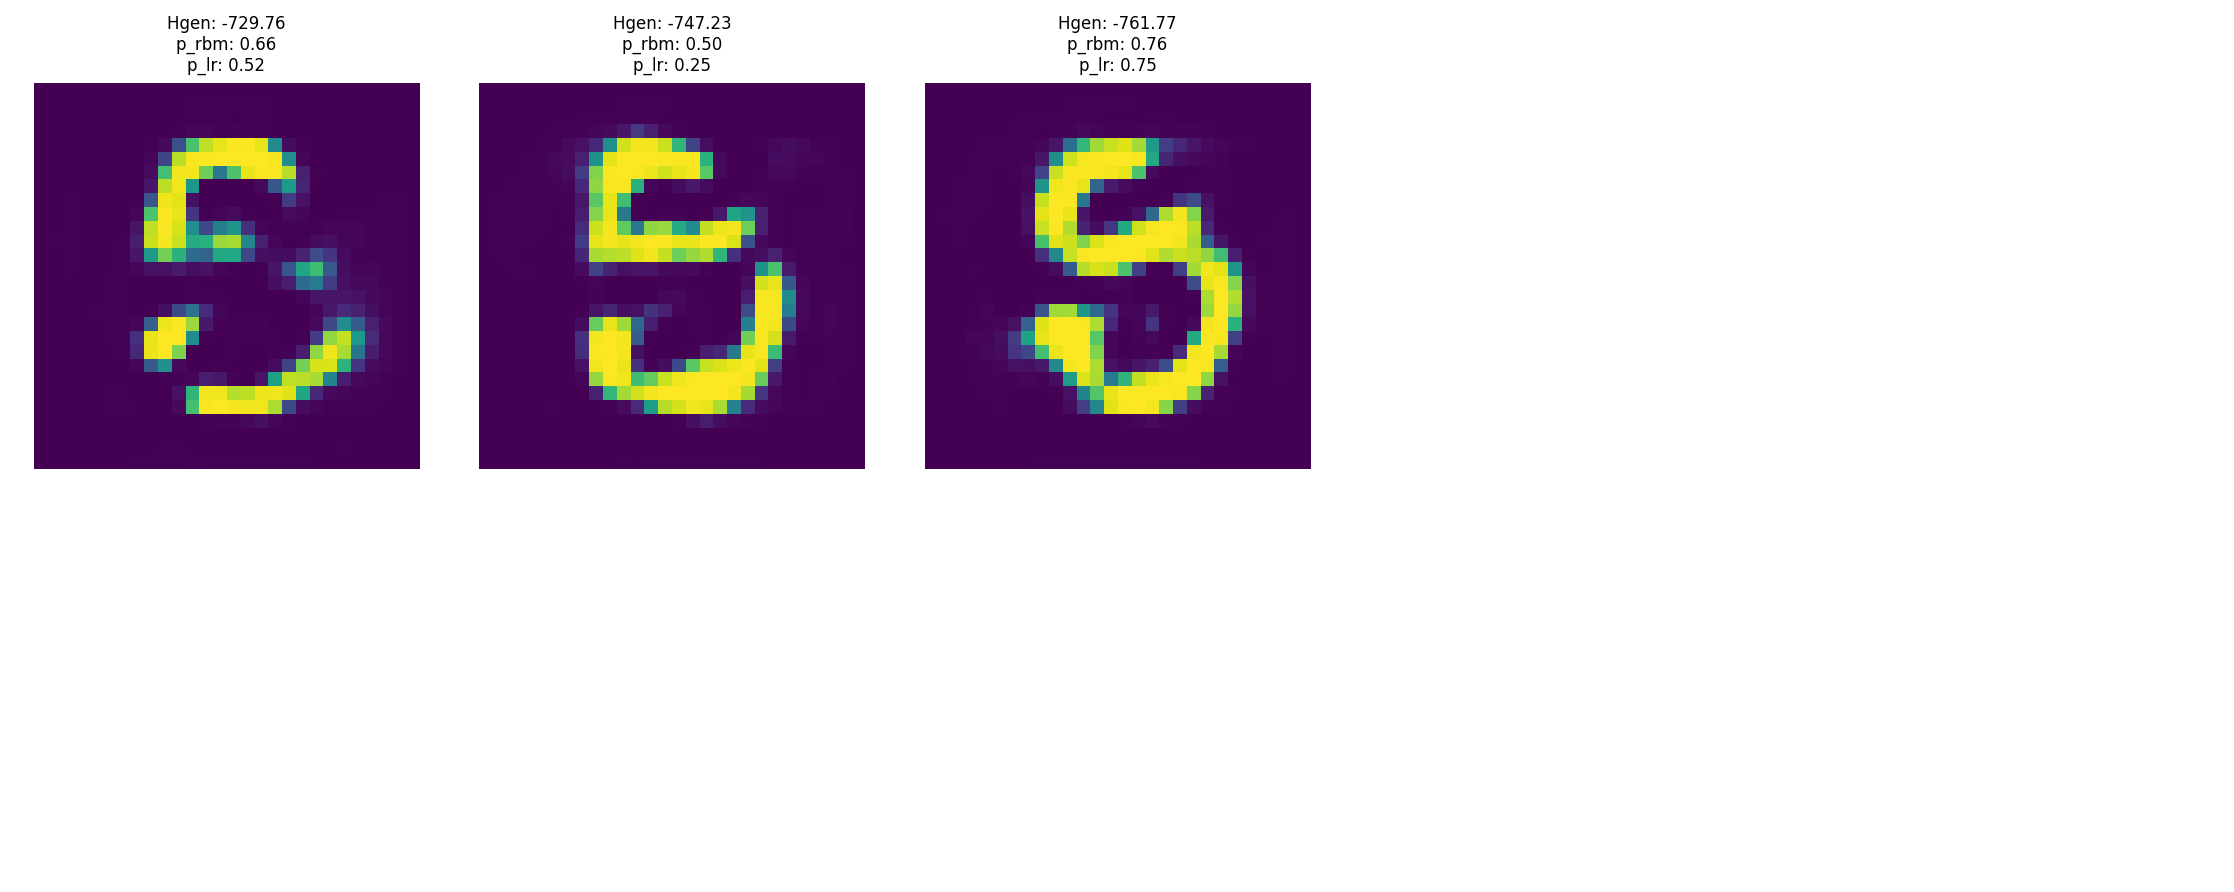

In [48]:
Hgen_max = -720
p_rbm_min = 0.5
p_lr_min = 0.8
distance = 90

mask = (distance_to_energies[distance]["Hgen"] <= Hgen_max) & (distance_to_energies[distance]["p_rbm"] >= p_rbm_min)
#mask = (distance_to_energies[distance]["Hgen"] <= Hgen_max) & (distance_to_energies[distance]["p_lr"] >= p_lr_min)
samples_selected = distance_to_energies[distance]["samples"][mask]
Hgen_selected = distance_to_energies[distance]["Hgen"][mask]
p_rbm_selected = distance_to_energies[distance]["p_rbm"][mask]
p_lr_selected = distance_to_energies[distance]["p_lr"][mask]

fig, ax = plt.subplots(1, 1, figsize=(15, 5), dpi=100)
ax.imshow(wild_type.reshape(28, 28).cpu().numpy(), cmap="viridis")
ax.set_title("Wild Type", fontsize=14)
ax.axis("off")
plt.show()

fig, axes = plt.subplots(2, 5, figsize=(15, 6), dpi=150)
for i, ax in enumerate(axes.flat):
    if i < len(samples_selected):
        ax.imshow(samples_selected[i].reshape(28, 28), cmap="viridis")
        ax.set_title(f"Hgen: {Hgen_selected[i]:.2f}\np_rbm: {p_rbm_selected[i]:.2f}\np_lr: {p_lr_selected[i]:.2f}", fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()



In [ ]:
label_pattern = widgets.IntText(min=0, max=9, step=1, value=0, description="Pattern:")

def plot_patterns(label_pattern):
    # get RBM patterns
    mag_prototype = rbm.params["label_matrix"][label_pattern]
    pattern_rbm = (rbm.params["weight_matrix"] @ mag_prototype).cpu().numpy().reshape(28, 28)

    # get_logreg_patterns
    pattern_lr = logreg.coef_[label_pattern].reshape(28, 28)
    
    # plot the patterns
    fig, ax = plt.subplots(1, 2, figsize=(8, 4), dpi=100)
    ax[0].imshow(pattern_rbm, cmap="viridis")
    ax[0].set_title("RBM Patterns")
    ax[0].axis("off")
    
    ax[1].imshow(pattern_lr, cmap="viridis")
    ax[1].set_title("Logistic Regression Patterns")
    ax[1].axis("off")
    
    plt.show()

interaction = widgets.interact(plot_patterns, label_pattern=label_pattern)

interactive(children=(IntText(value=0, description='Pattern:'), Output()), _dom_classes=('widget-interact',))